# Cross-day unit matching - mouse 4103, Sept 15-18 (training window)

**What this does.** For every pair of days it asks, for every good unit, "is this the same neuron as any
unit on the other day?", and returns a probability. Neurons are then followed across several days at
chosen confidence levels (posterior of every link >= 0.6 / 0.7 / 0.8 / 0.9 / 0.95).

**What it uses** (nothing behavioural): the spatial waveform footprint on the physical electrodes
(raw waveforms, two halves of each recording), depth and lateral position after drift correction,
autocorrelogram and ISI shape, firing rate.

**How the probabilities are made honest.**
* *Different neuron* reference = pairs of different units from the same recording that sit close together on the probe.
* *Same neuron* is learned from the cross-day data (EM), starting from obvious matches; each unit gets at most one partner.
* **Decoy test:** the matching is repeated with the other day displaced by 160-320 um; any "match" it finds there is false,
  which measures the false-match rate at each level directly (panel C of the overview).

**Reading the plots.** Pair pages show the two units' best-channel waveforms, amplitude along the probe, autocorrelograms
and probe positions overlaid, plus bars showing which features argued for (green) or against (red) the match.

In [1]:
import sys
from pathlib import Path
REPO = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "fmpipe").is_dir())
sys.path.insert(0, str(REPO))

import matplotlib.pyplot as plt
import pandas as pd
from fmpipe import SessionConfig
from fmpipe.matching import (extract_waveforms, match_all, load_matching, plot_pair_pages,
                             plot_chain_pages, plot_overview)

In [2]:
# --- CONFIG -------------------------------------------------------------------
ROOTS = (r"C:\Users\Shermanlab\Documents\Open Ephys", "Z:/")
def cfg(session, experiment=1):
    return SessionConfig(data_root="K:/", session=session, experiment=experiment, ks_search_roots=ROOTS)

DAYS = {                                   # label -> session (in chronological order)
    # Sept 14 is left out: a short, differently structured (static-shaping) session with only 112 good units;
    # Sept 15-18 are the training window analysed here.
    "09-15": cfg("2026-09-15_14-22-37"),
    "09-16": cfg("2026-09-16_13-21-12", experiment=2),
    "09-17": cfg("2026-09-17_12-22-54"),
    "09-18": cfg("2026-09-18_11-22-28"),
}
OUT_DIR = r"D:\Neuropixels data-motor project\unit_matching\4103_sept15-18"   # tables, PDFs, workbook, pickle
LEVELS = (0.6, 0.7, 0.8, 0.9, 0.95)
SHOW_LEVEL = 0.8                           # level used for the example pages below

In [3]:
# --- step 1: raw mean waveforms (two halves) of every good unit (~4 min per day, skipped if done) ---
for d, c in DAYS.items():
    extract_waveforms(c)

waveforms exist: waveforms.npz (use force=True to recompute)
waveforms exist: waveforms.npz (use force=True to recompute)
waveforms exist: waveforms.npz (use force=True to recompute)
waveforms exist: waveforms.npz (use force=True to recompute)


In [4]:
# --- step 2: match every pair of days, estimate false-match rates, track neurons across days ---
out = match_all(DAYS, OUT_DIR, levels=LEVELS)
days, profiles, results = out["days"], out["profiles"], out["results"]
out["summary"]

reference: 16694 different-unit neighbour pairs, 805 same-unit split-half pairs


09-15 vs 09-16: drift   +3.2 um |  34 matches at p>=0.8 (73 at >=0.6)


09-15 vs 09-17: drift   +4.0 um |  50 matches at p>=0.8 (78 at >=0.6)


09-15 vs 09-18: drift   +7.2 um |  49 matches at p>=0.8 (76 at >=0.6)


09-16 vs 09-17: drift   +1.1 um |  61 matches at p>=0.8 (86 at >=0.6)


09-16 vs 09-18: drift   +4.3 um |  57 matches at p>=0.8 (89 at >=0.6)


09-17 vs 09-18: drift   +2.7 um |  74 matches at p>=0.8 (92 at >=0.6)


,level,>=2 days,>=3 days,>=4 days
0,0.60,172,81,27
1,0.70,157,66,20
2,0.80,131,52,10
3,0.90,107,32,4
4,0.95,85,22,3


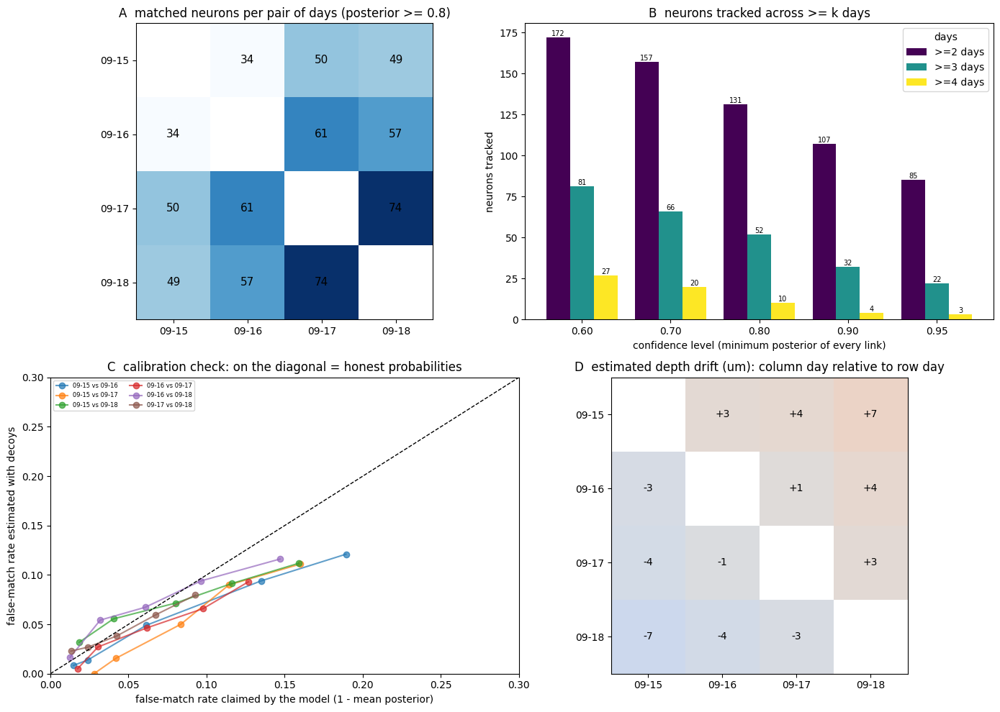

In [5]:
# --- overview: matches per pair of days, tracked neurons per confidence level, calibration, drift ---
plot_overview(results, days, out["summary"], out["fdr"], level_for_matrix=SHOW_LEVEL,
              save_path=OUT_DIR + r"\overview.png"); plt.show()

In [6]:
# --- false-match rate at each confidence level (decoy test), per pair of days ---
fdr = pd.concat({f"{a} vs {b}": f for (a, b), f in out["fdr"].items()}, names=["days"]).reset_index(level=0)
fdr.pivot(index="days", columns="level", values="est_fdr").round(3)

level,0.60,0.70,0.80,0.90,0.95
days,,,,,
09-15 vs 09-16,0.121,0.094,0.049,0.014,0.008
09-15 vs 09-17,0.111,0.090,0.050,0.016,0.000
09-15 vs 09-18,0.112,0.091,0.071,0.056,0.032
09-16 vs 09-17,0.093,0.066,0.046,0.027,0.005
09-16 vs 09-18,0.116,0.094,0.067,0.054,0.017
09-17 vs 09-18,0.080,0.060,0.038,0.027,0.023


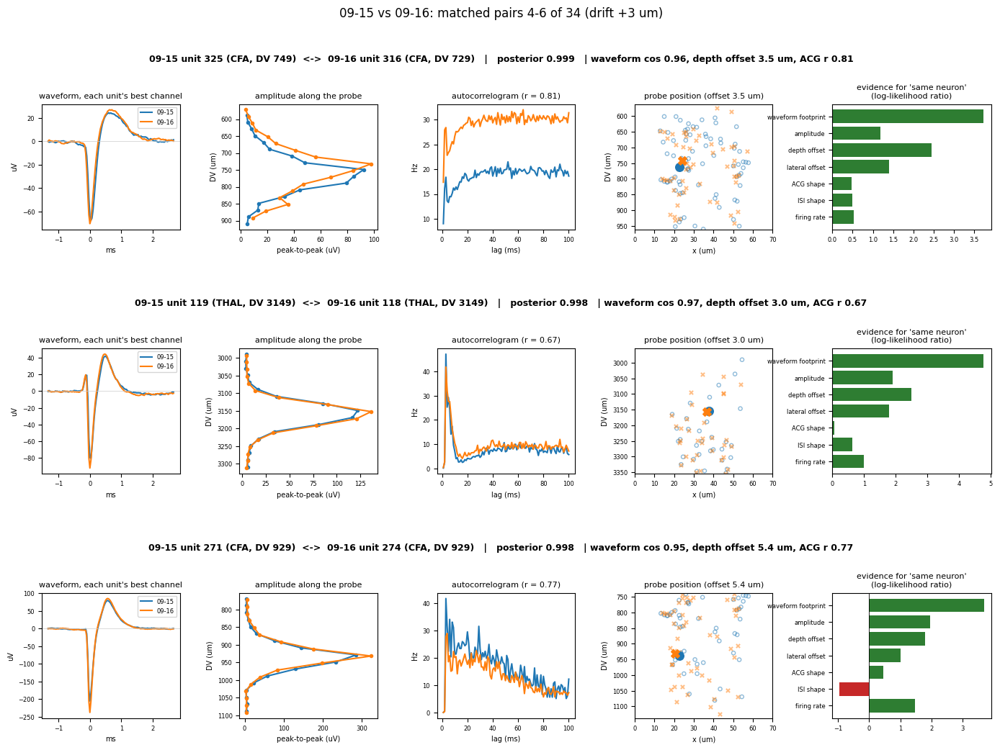

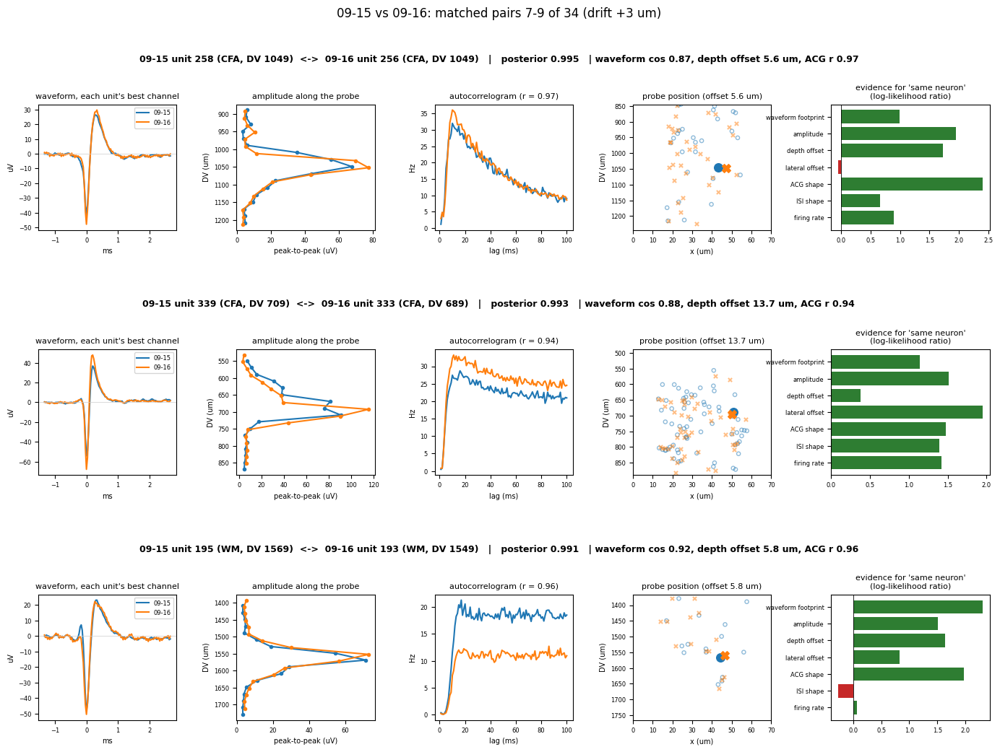

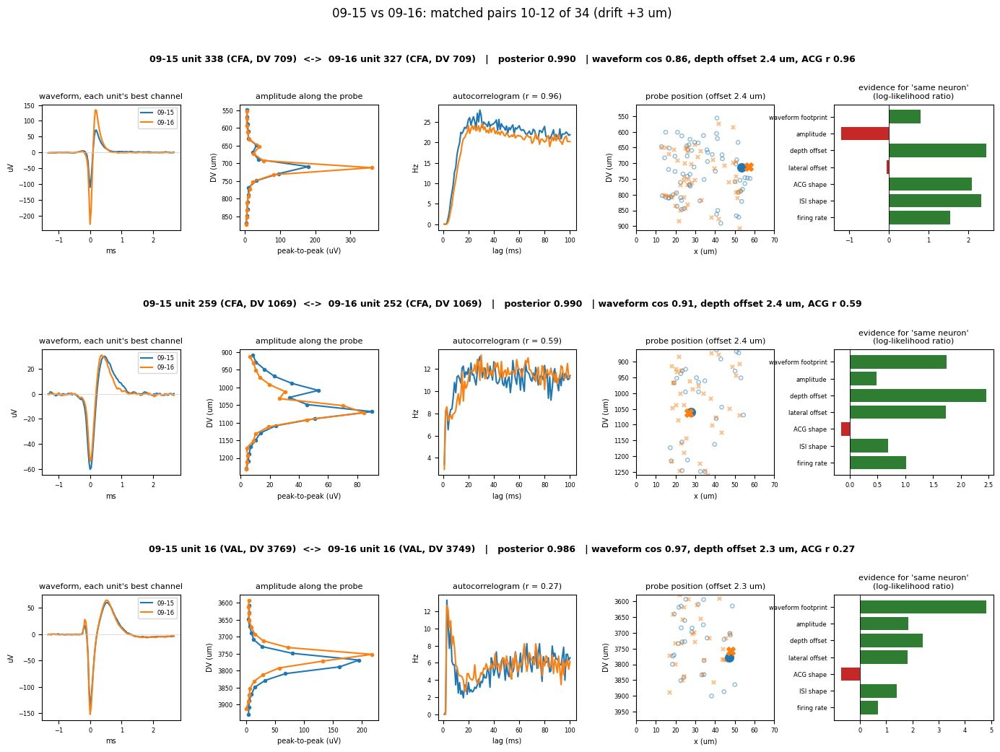

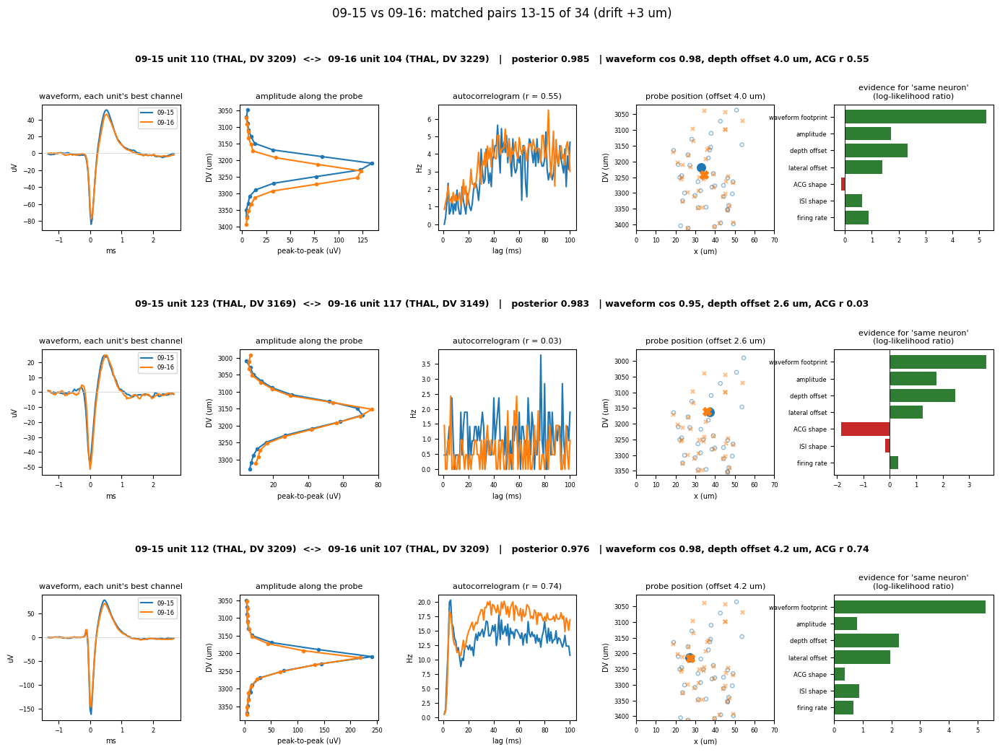

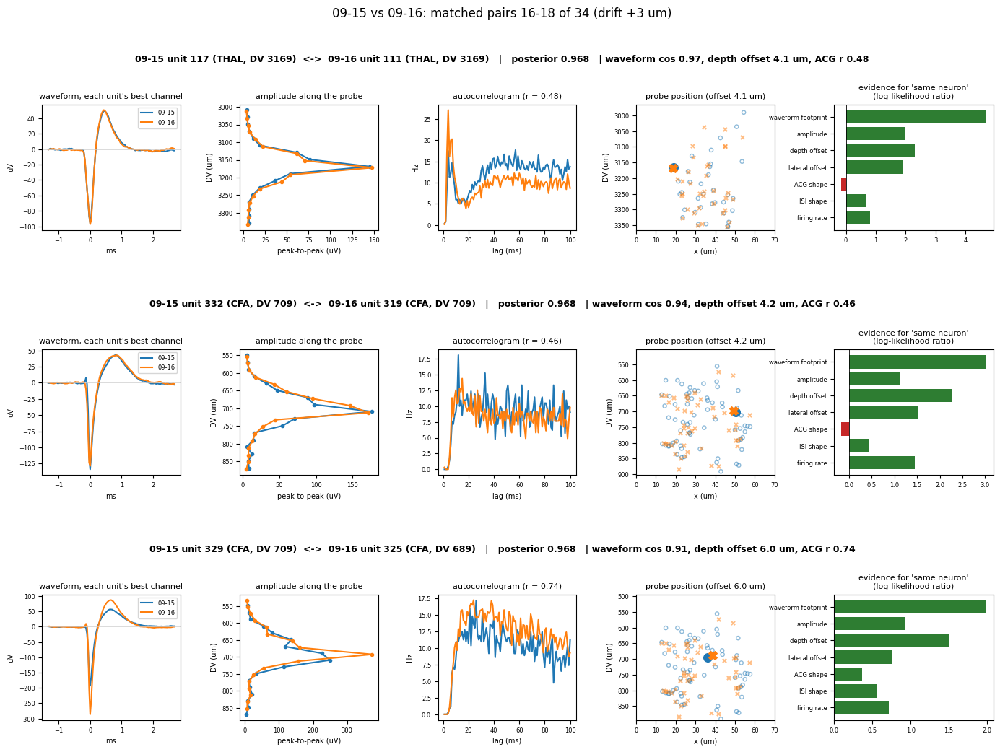

...

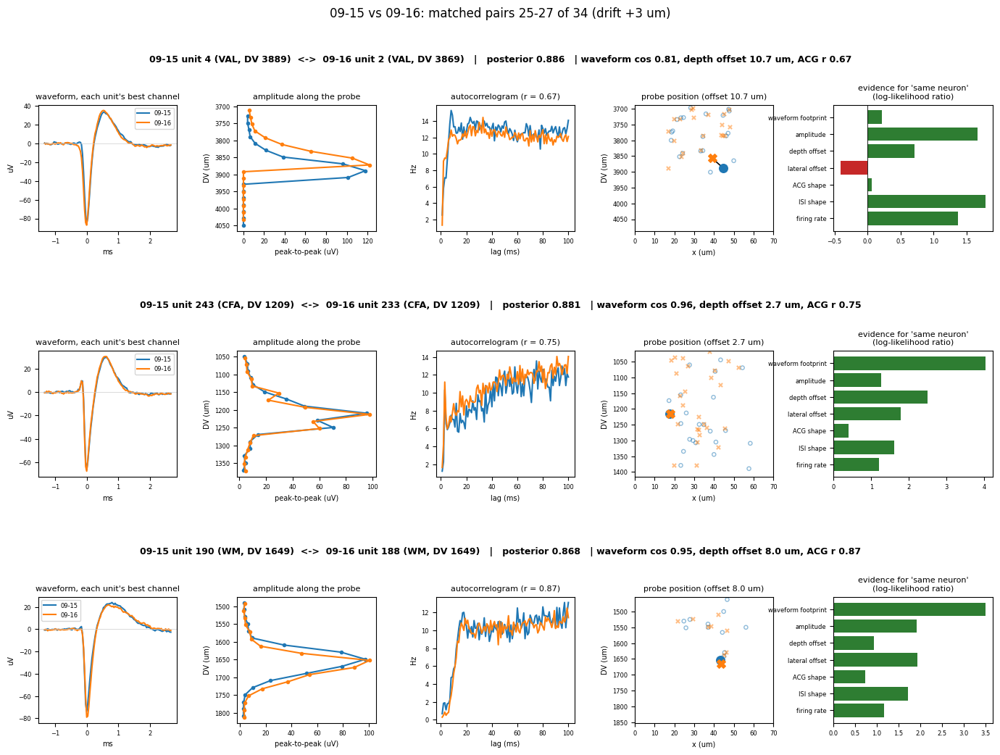

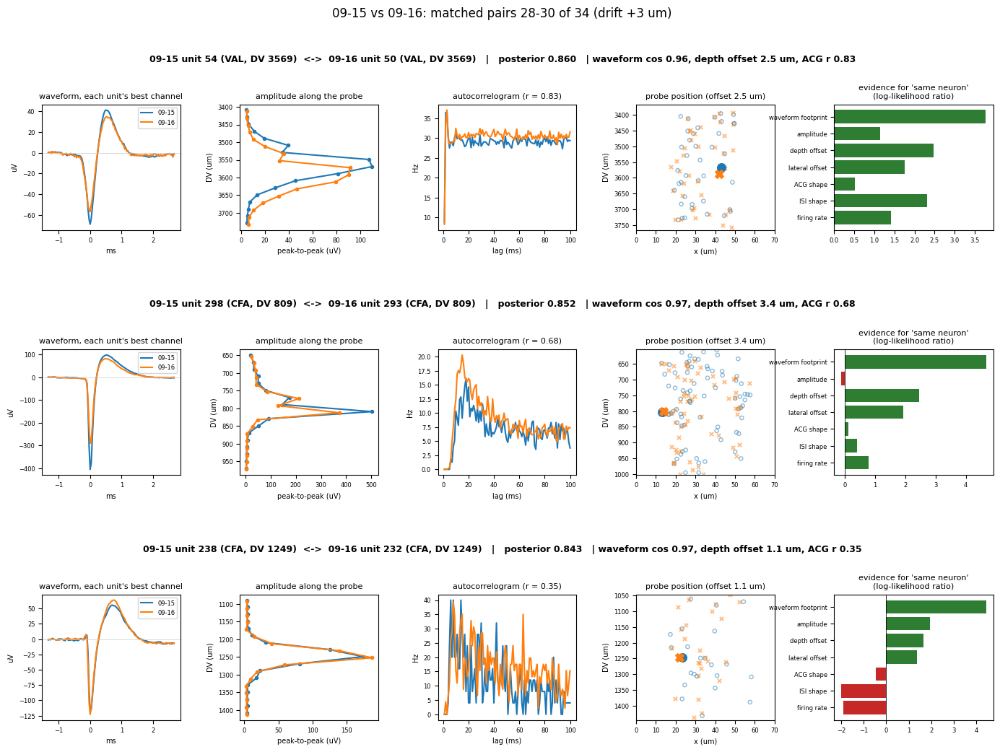

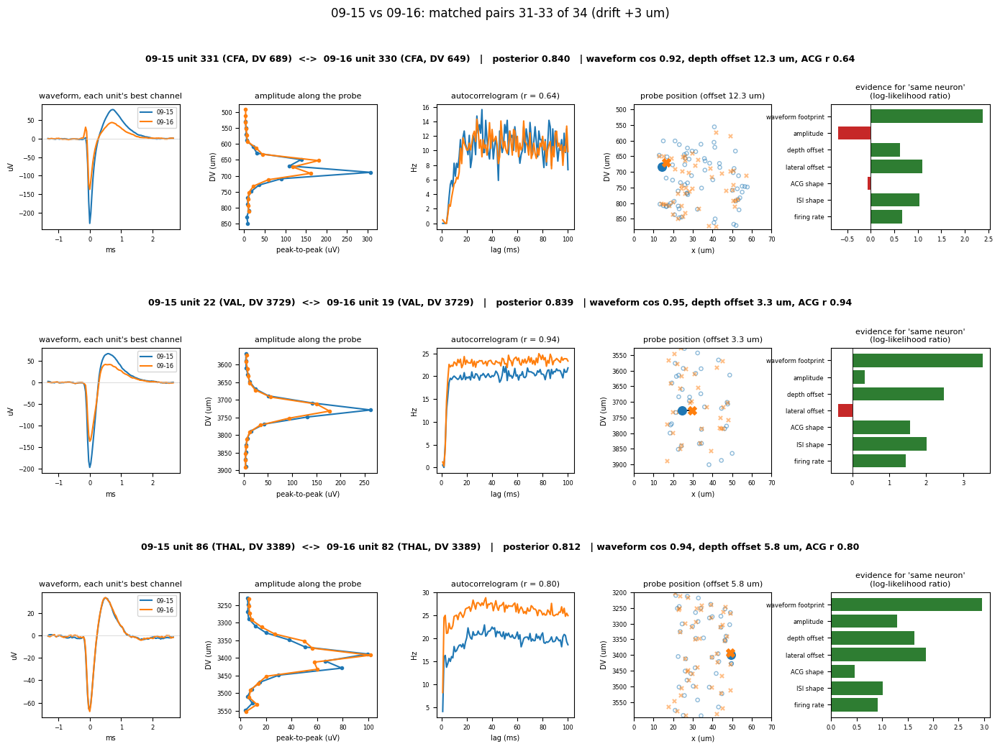

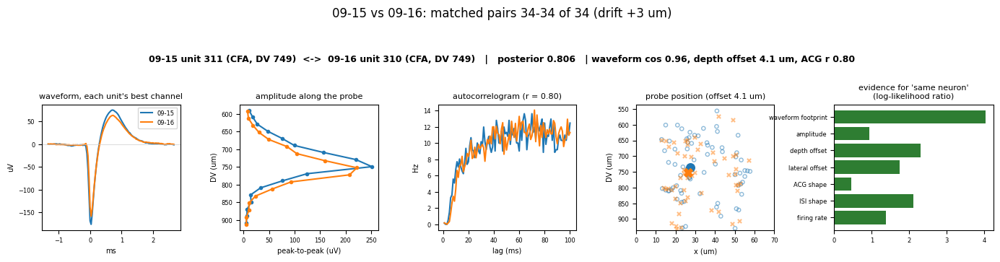

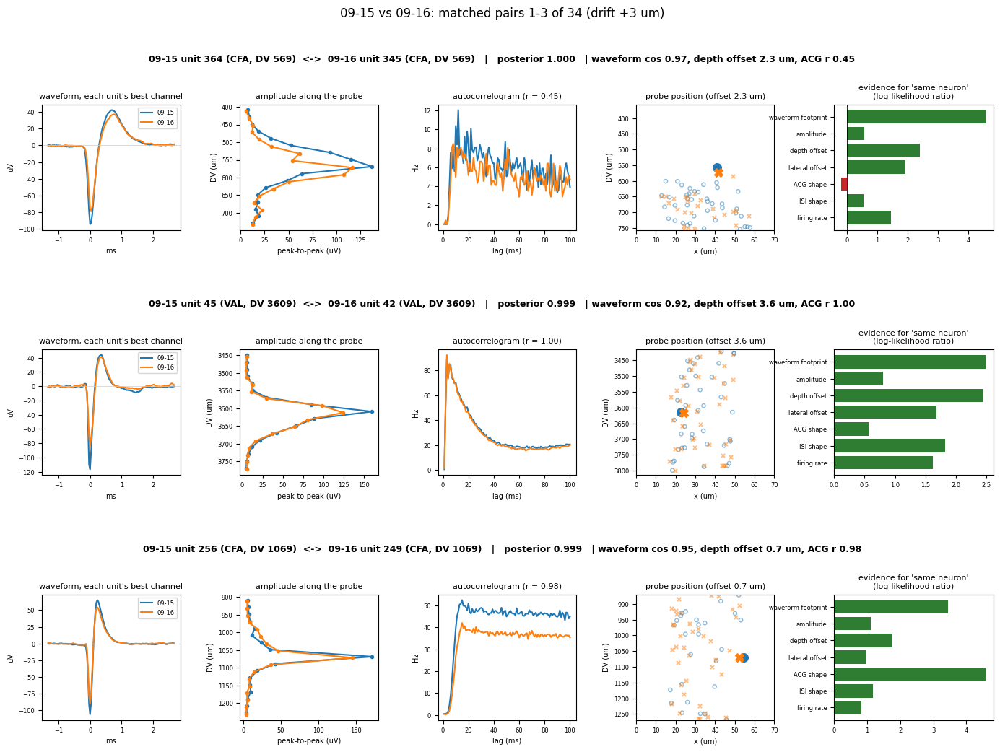

<Figure size 640x480 with 0 Axes>

In [7]:
# --- example matched pairs for one pair of days (the full set is saved as a PDF) ---
A, B = "09-15", "09-16"
figs = plot_pair_pages(results[(A, B)], profiles[A], profiles[B], pdf_path=OUT_DIR + rf"\pairs_{A}_vs_{B}.pdf",
                       min_p=SHOW_LEVEL, per_page=3)
for f in figs[:2]:
    plt.figure(f.number); plt.show()

n_days            2   3   4
neurons tracked  79  42  10


C:\NeuropixelsAnalysisModules_kpk\NeuropixelsAnalysisPipeline\fmpipe\matching\plots.py:139: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`). Consider using `matplotlib.pyplot.close()`.
  fig = plt.figure(figsize=(17, 4.1 * per_page))


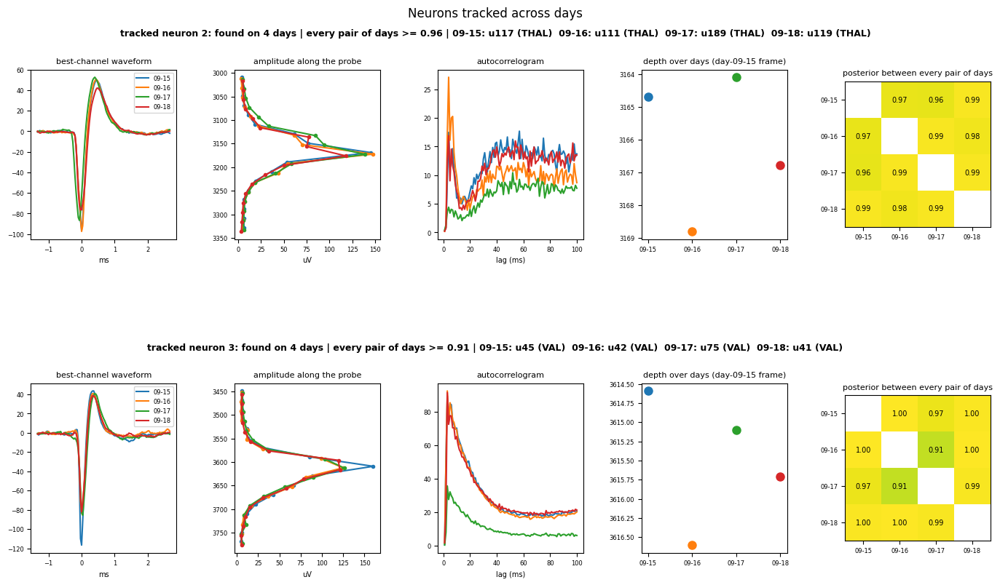

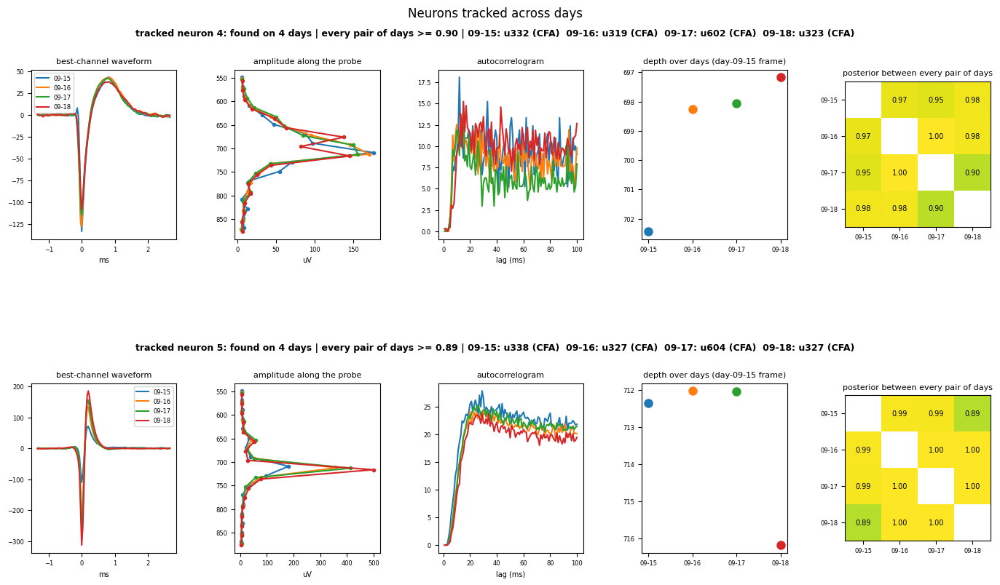

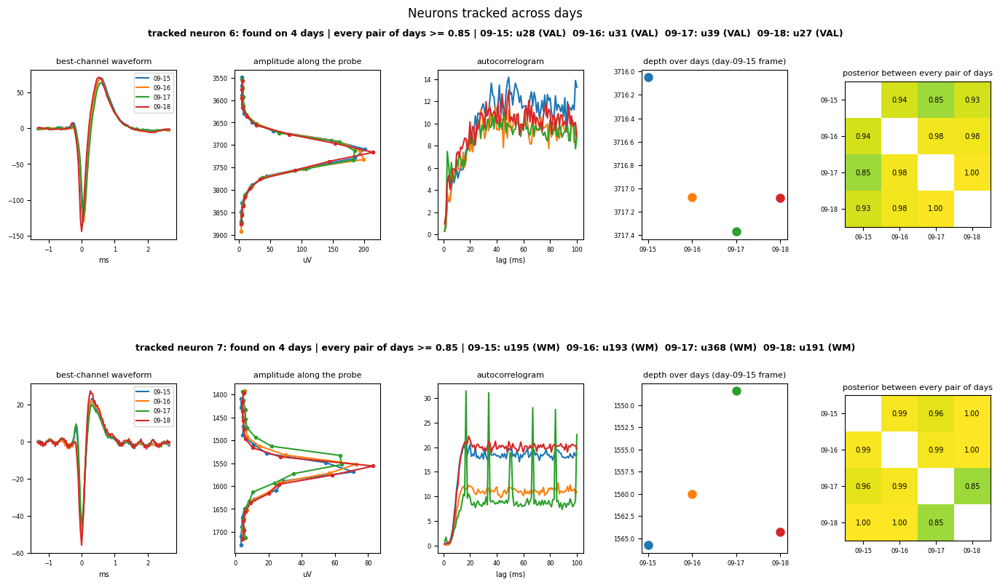

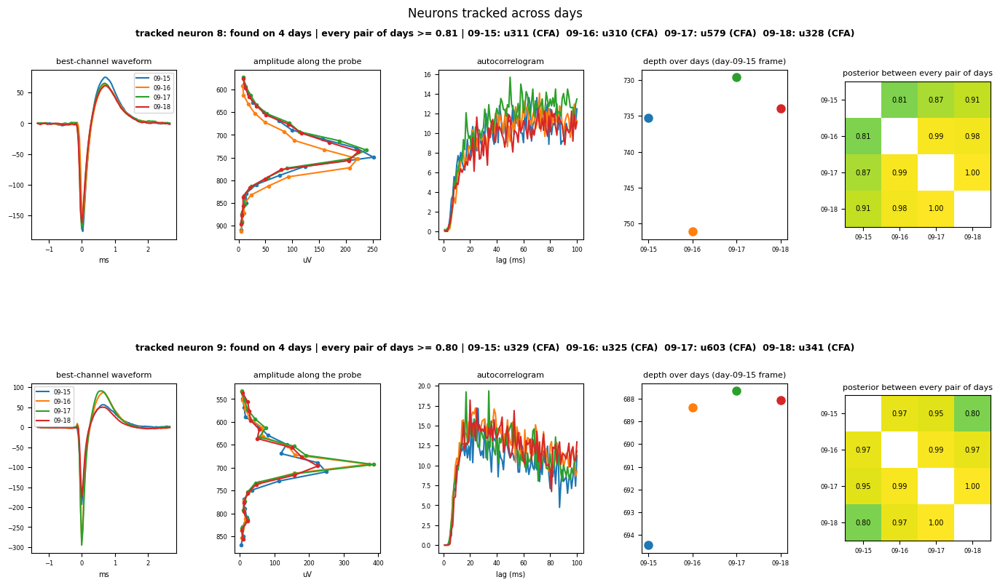

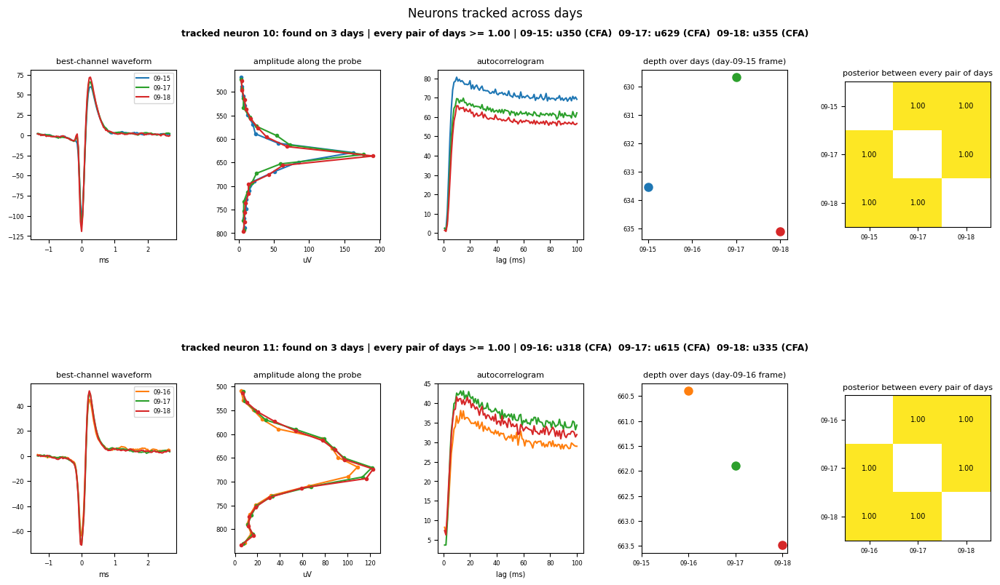

...

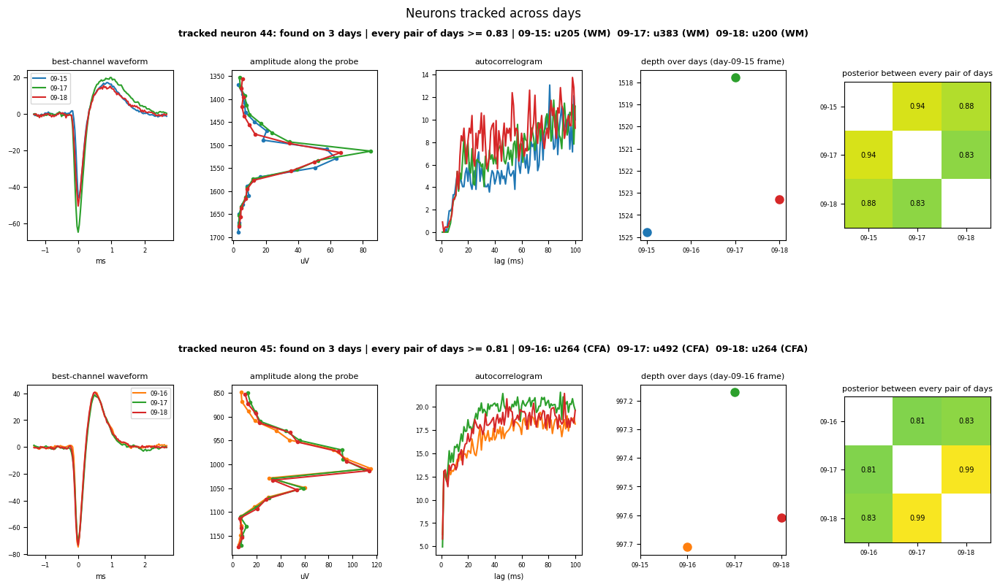

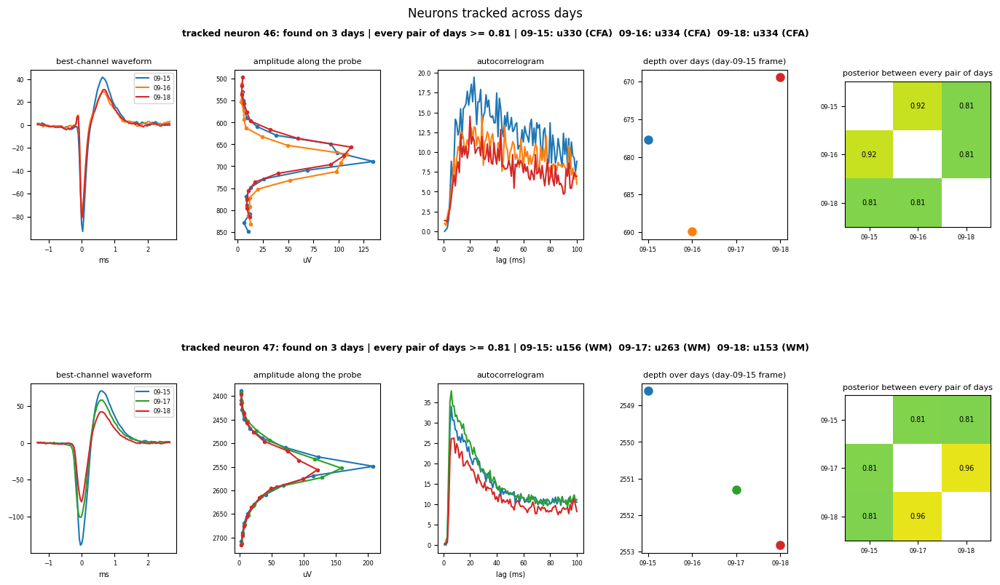

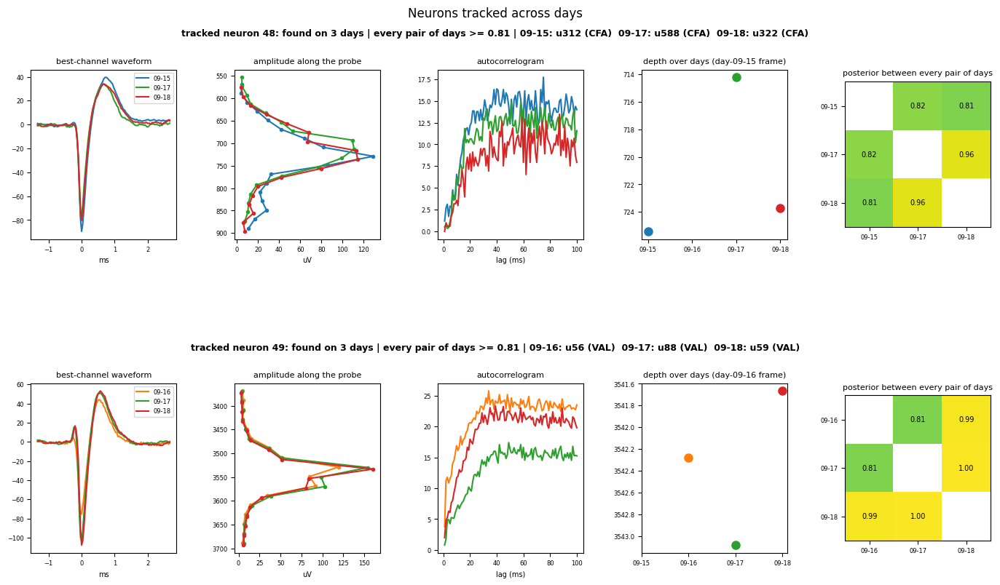

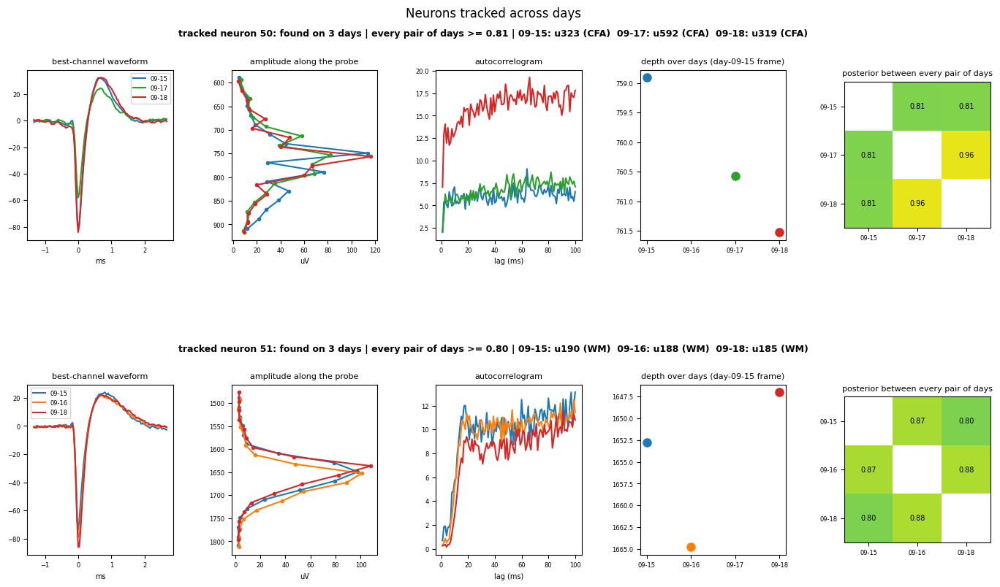

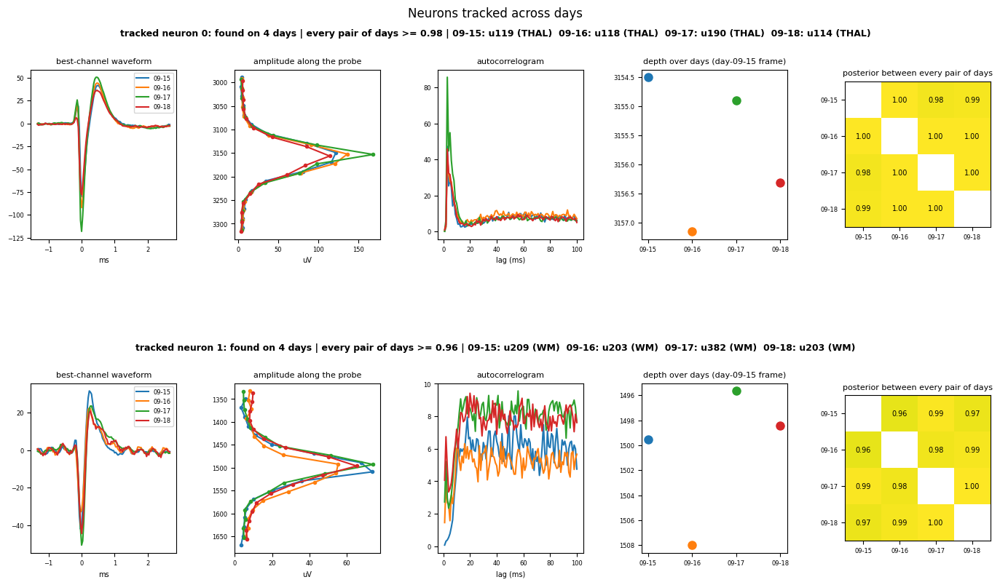

<Figure size 640x480 with 0 Axes>

<Figure size 640x480 with 0 Axes>

In [8]:
# --- neurons tracked across >= 3 days at SHOW_LEVEL (full set saved as PDF) ---
ch = out["chains"][SHOW_LEVEL]
print(ch.groupby("n_days").size().rename("neurons tracked").to_frame().T.to_string())
figs = plot_chain_pages(ch, profiles, results, days, pdf_path=OUT_DIR + rf"\tracked_neurons_p{SHOW_LEVEL:.2f}.pdf", min_days=3)
for f in figs[:3]:
    plt.figure(f.number); plt.show()

level 0.6: 27 neurons found on all 4 days


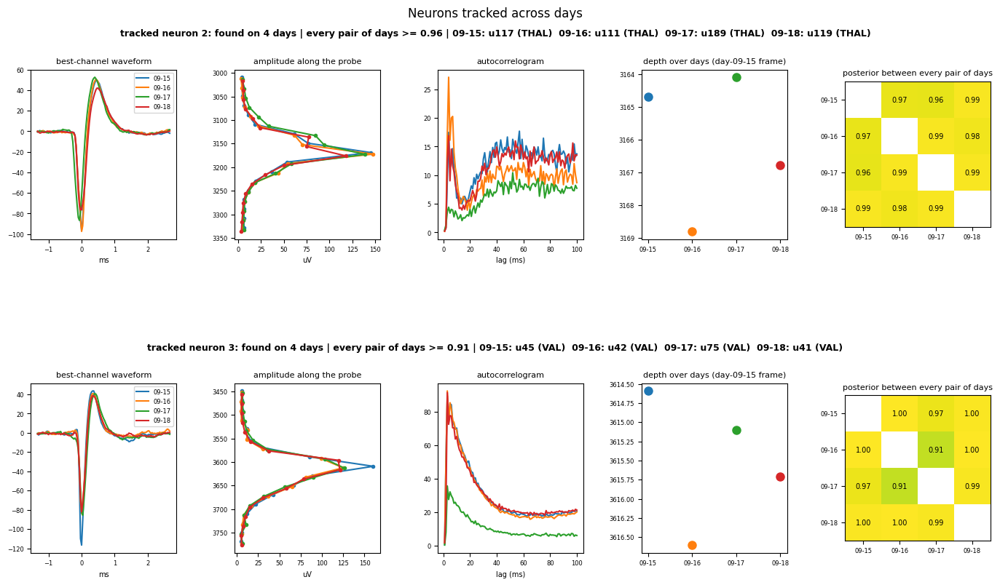

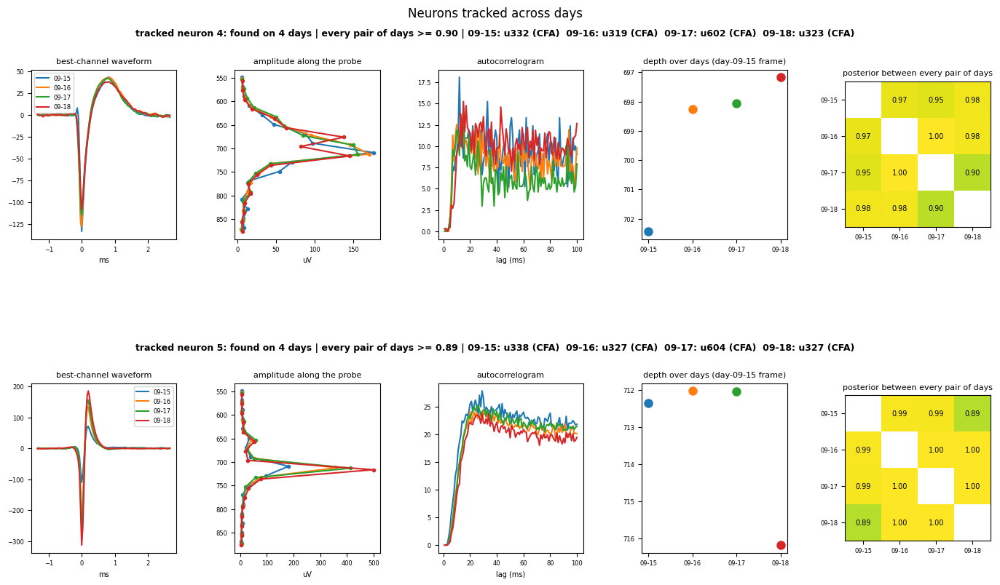

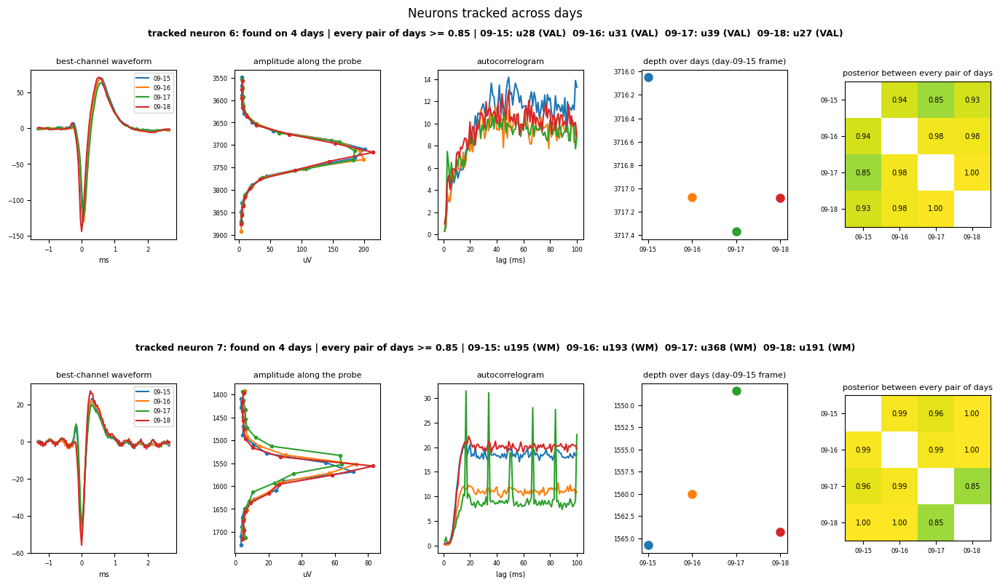

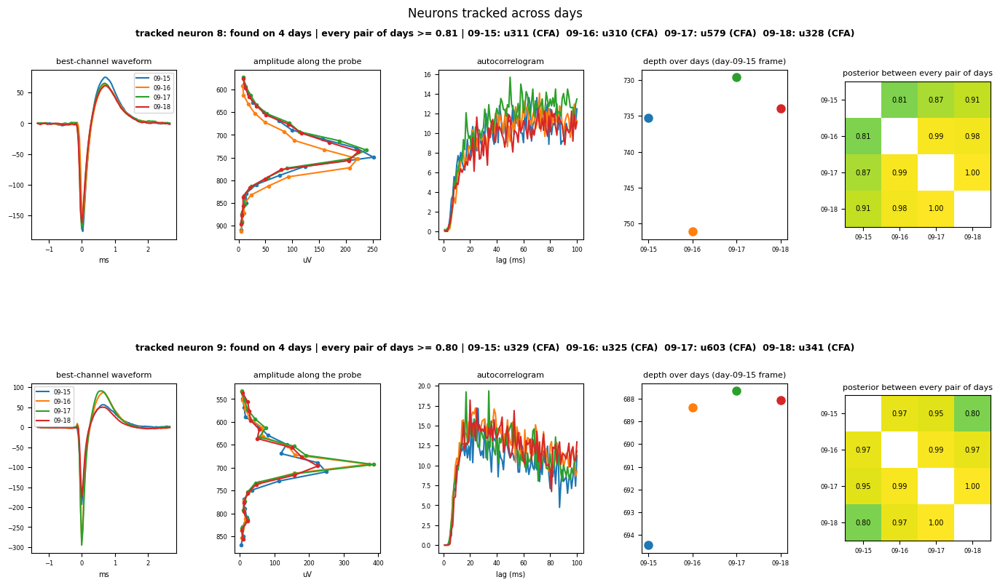

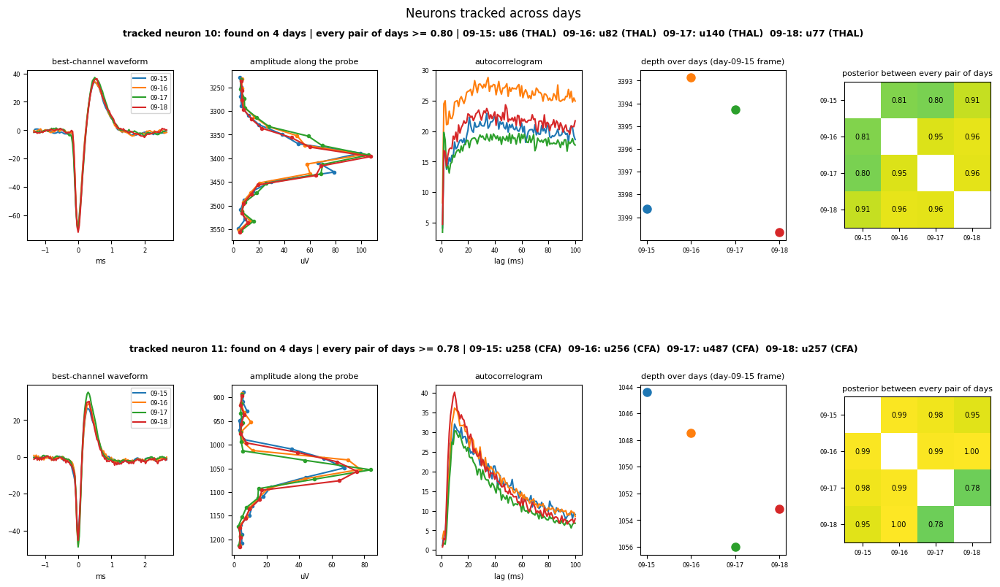

...

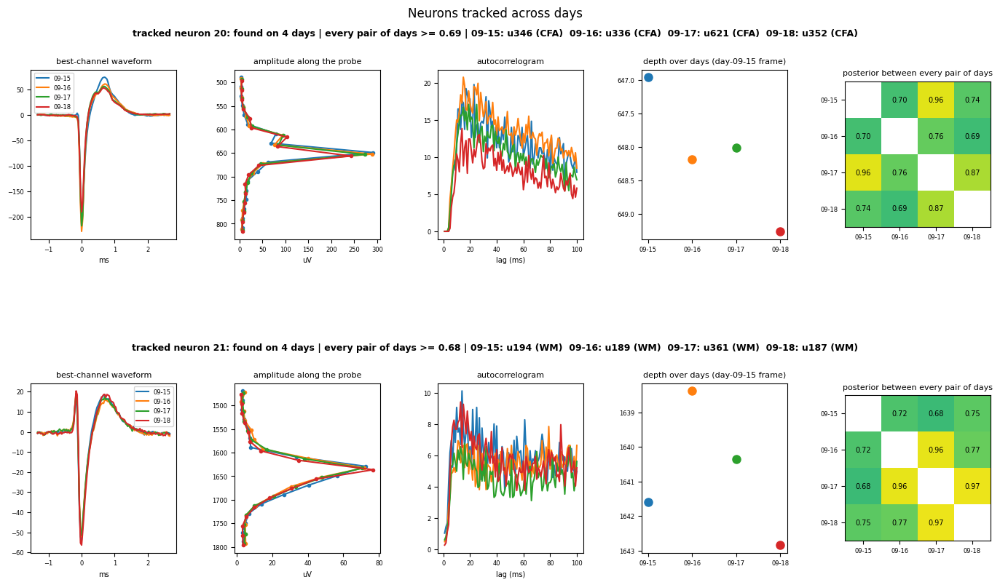

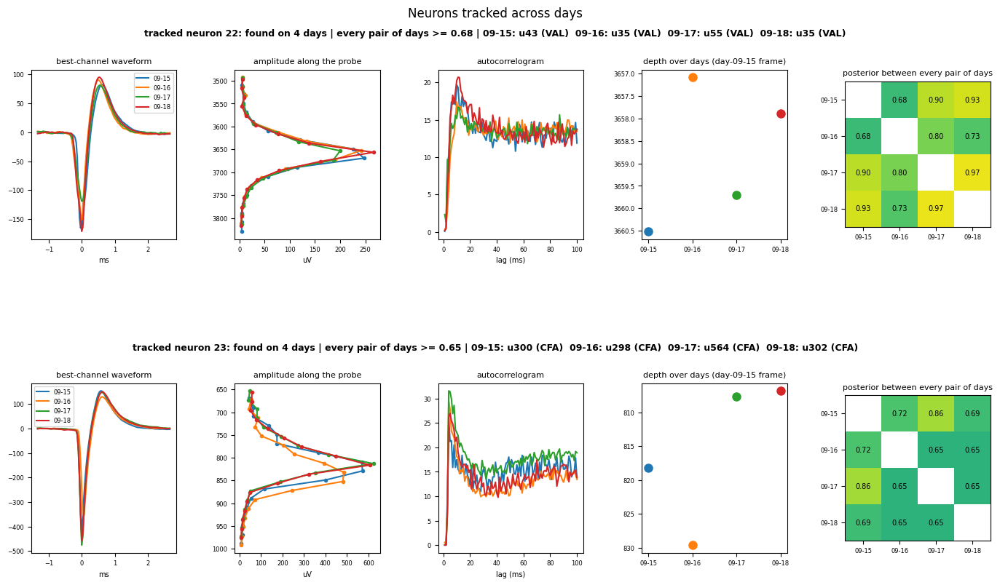

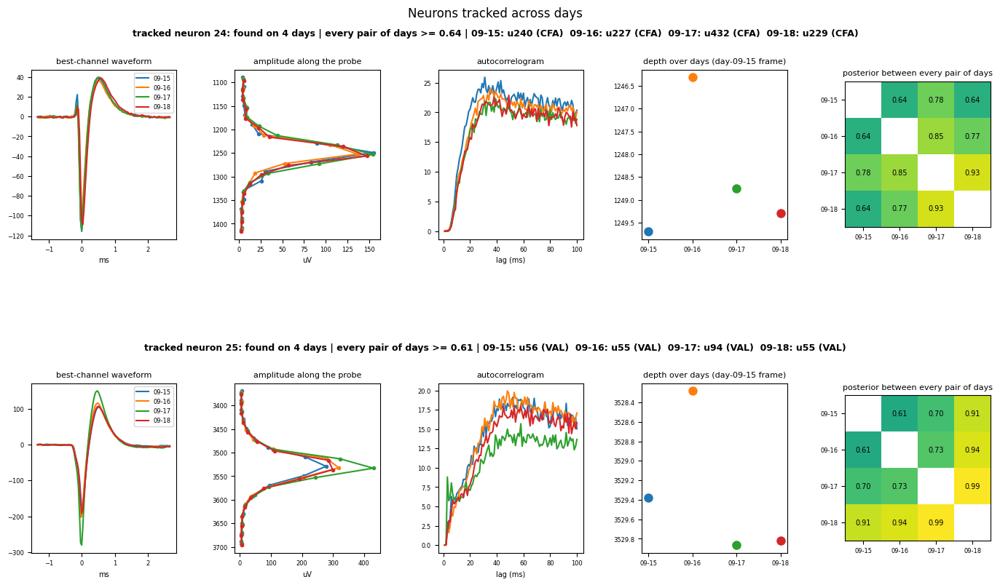

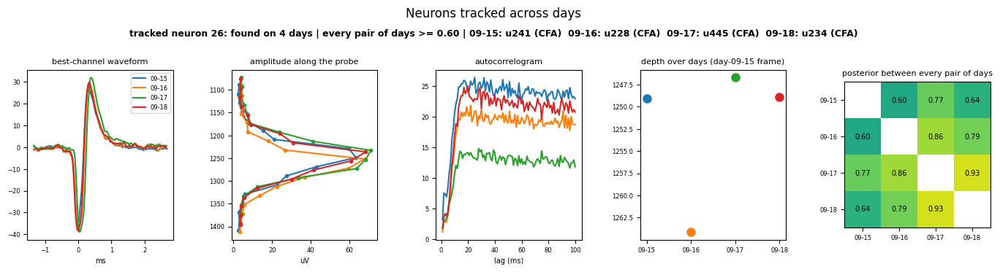

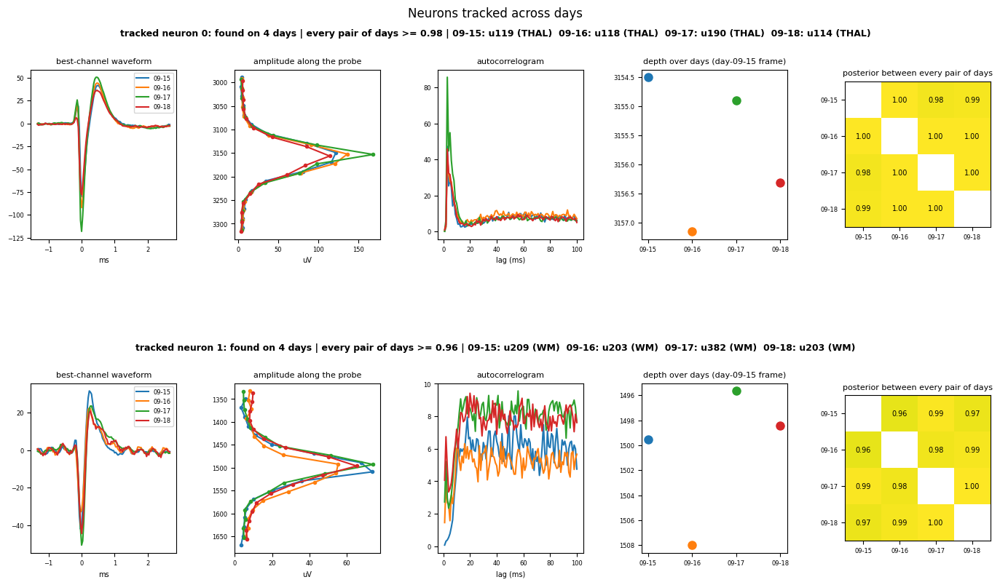

<Figure size 640x480 with 0 Axes>

<Figure size 640x480 with 0 Axes>

In [9]:
# --- the neurons followed across ALL days, at the most permissive level that finds any ---
for L in LEVELS:
    five = out["chains"][L]
    five = five[five.n_days == len(days)] if len(five) else five
    print(f"level {L}: {len(five)} neurons found on all {len(days)} days")
    if len(five):
        figs = plot_chain_pages(out["chains"][L], profiles, results, days,
                                pdf_path=OUT_DIR + rf"\neurons_on_all_days_p{L:.2f}.pdf", min_days=len(days))
        for f in figs[:3]:
            plt.figure(f.number); plt.show()
        break

In [10]:
# --- SEQUENTIAL tracking: follow each neuron day -> next day (a one-day gap is allowed). Slow changes are tolerated,
# non-adjacent pairs are not required to pass the level (their direct posterior is shown on the pages). ---
from fmpipe.matching.chains import sequential_summary
seq_tabs, seq_sum = sequential_summary(results, days, LEVELS, max_gap=1)
for L, t in seq_tabs.items():
    if len(t):
        t2 = t.copy(); t2["members"] = [{d: int(profiles[d].unit_ids[i]) for d, i in m.items()} for m in t.members]
        t2.to_csv(OUT_DIR + rf"\tracked_sequential_p{L:.2f}.csv", index=False)
seq_sum

,level,>=2 days,>=3 days,>=4 days
0,0.60,164,106,55
1,0.70,150,84,44
2,0.80,124,74,31
3,0.90,100,54,20
4,0.95,80,43,11


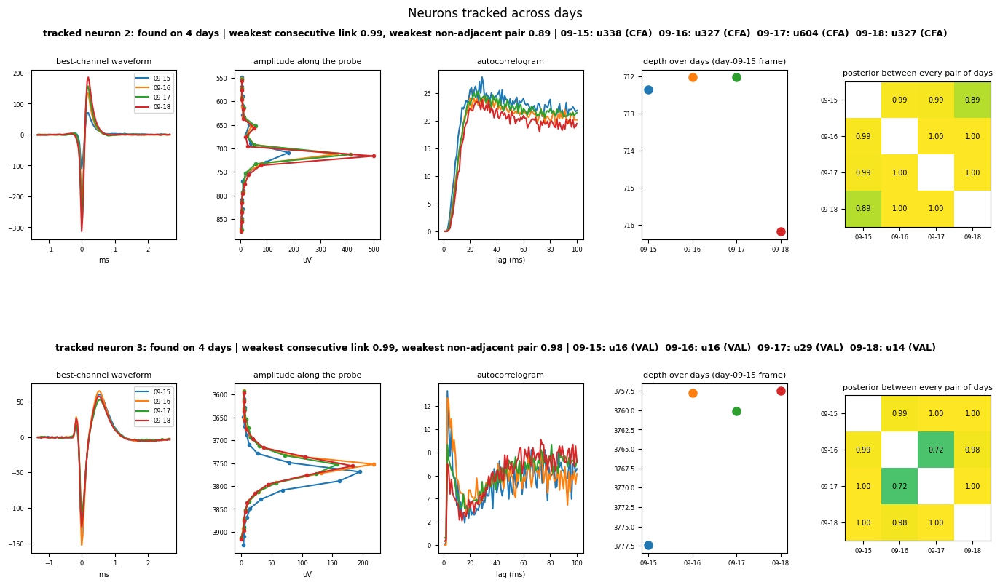

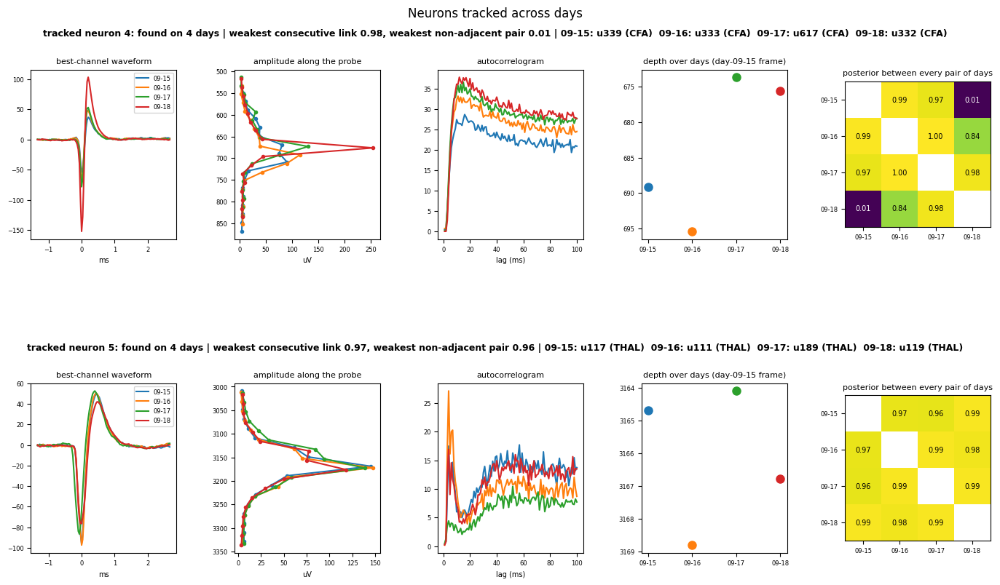

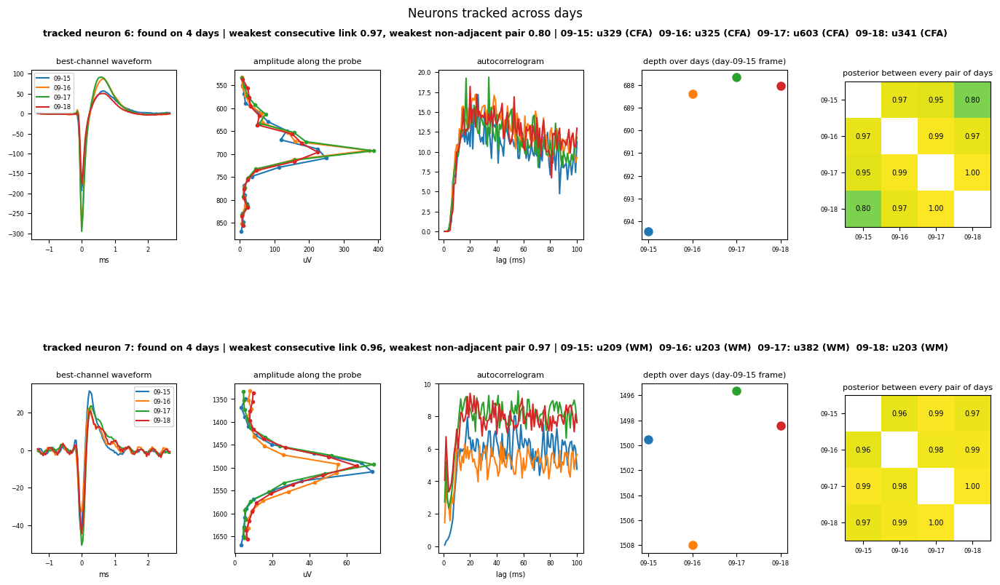

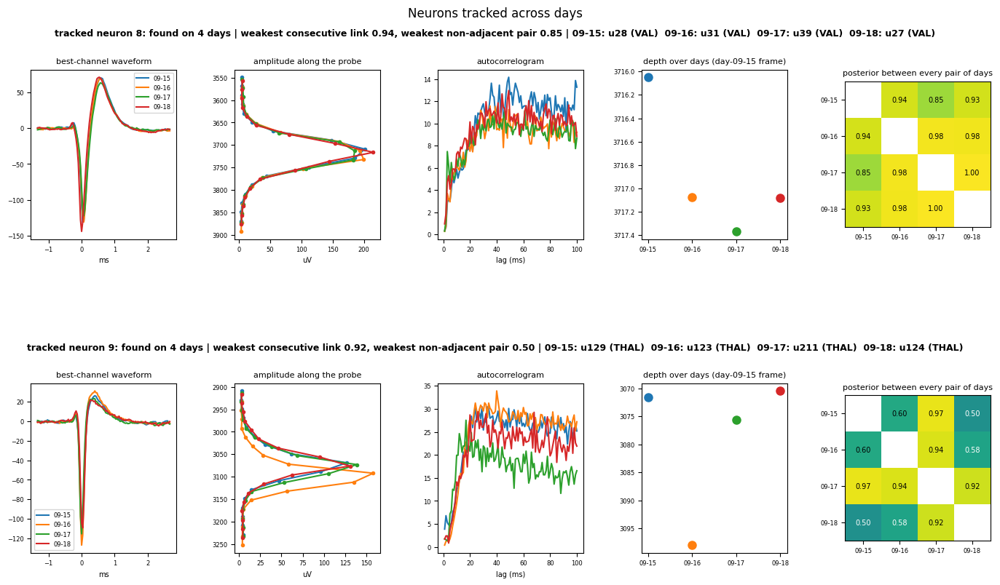

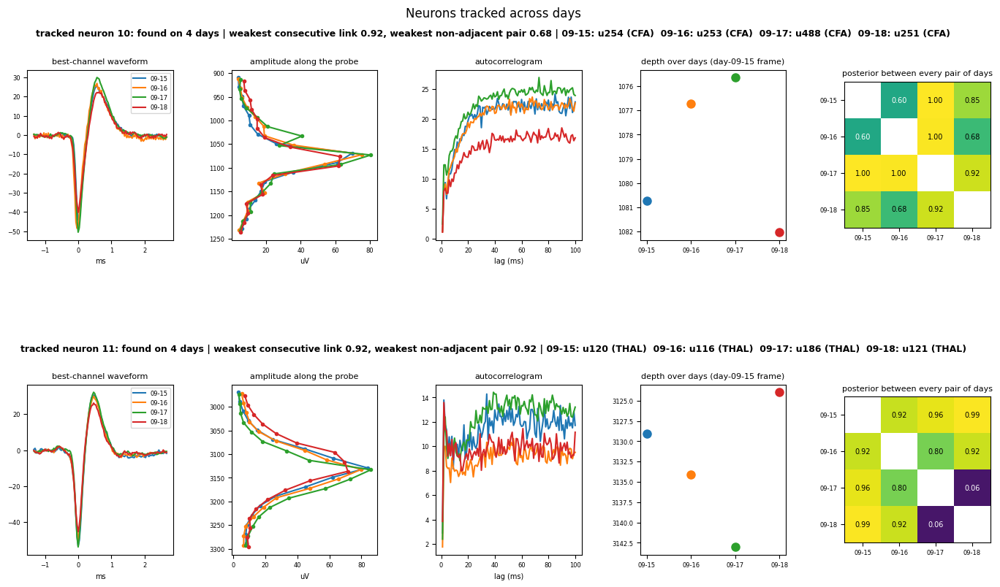

...

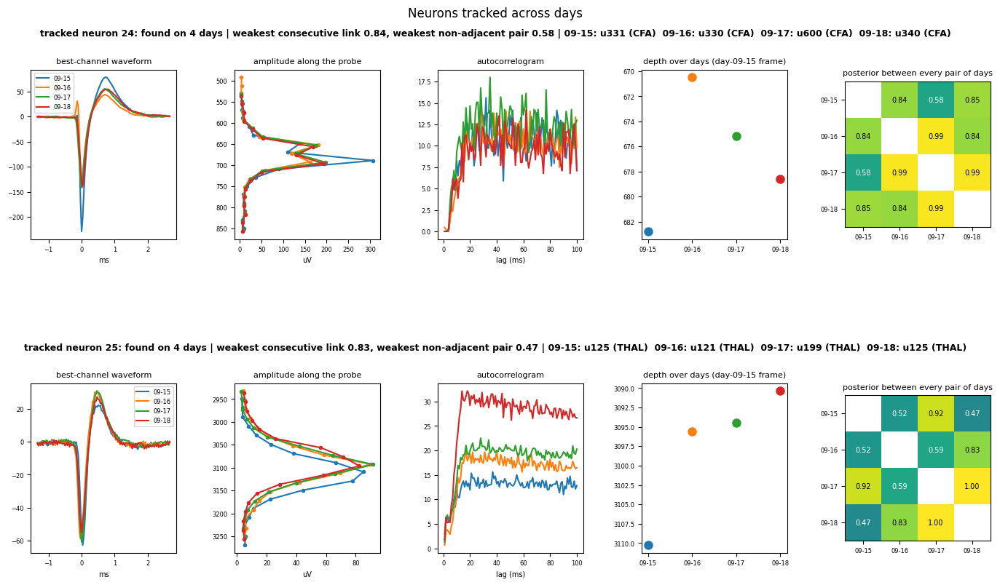

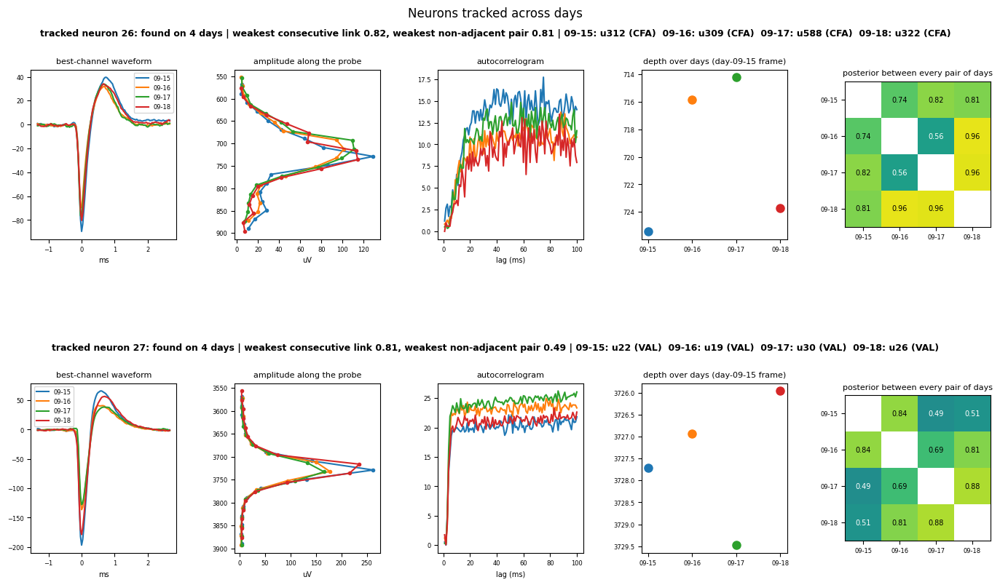

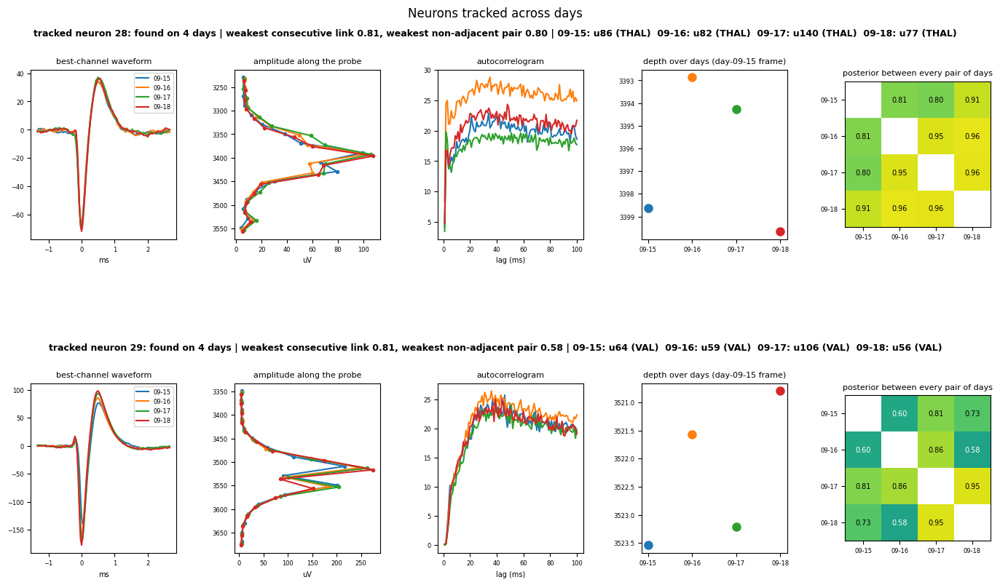

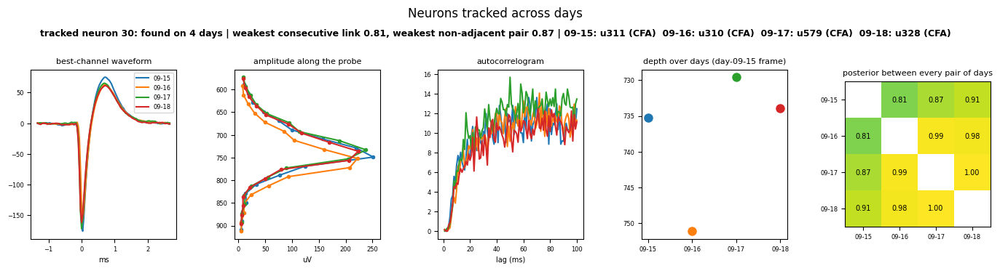

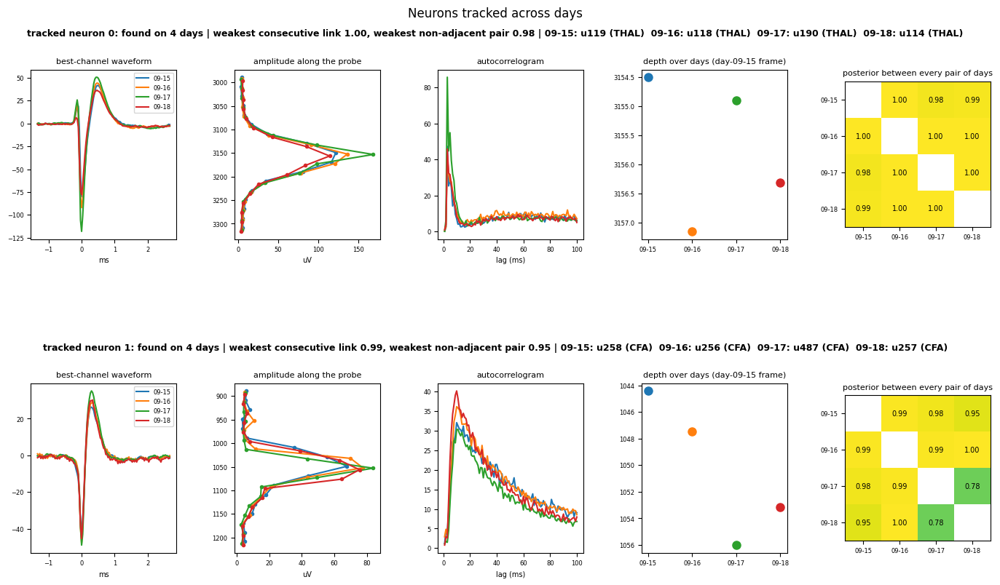

<Figure size 640x480 with 0 Axes>

<Figure size 640x480 with 0 Axes>

In [11]:
# --- neurons tracked on all 5 days by the sequential rule (look at the right-hand matrix: weak non-adjacent pairs
# mean the neuron looks different at the two ends, which is either slow change or a wrong link) ---
L = 0.8
figs = plot_chain_pages(seq_tabs[L], profiles, results, days, pdf_path=OUT_DIR + rf"\sequential_5day_p{L:.2f}.pdf", min_days=len(days))
for f in figs[:3]:
    plt.figure(f.number); plt.show()

In [12]:
# --- Excel workbook: summary, matches per pair, false-match rates, drift, one sheet per rule and level ---
from fmpipe.matching import write_datasheets
xlsx = write_datasheets(out, DAYS, OUT_DIR + r"\\tracked_neurons_sept15-18.xlsx", levels=LEVELS)
print("workbook:", xlsx)

C:\NeuropixelsAnalysisModules_kpk\NeuropixelsAnalysisPipeline\fmpipe\matching\datasheets.py:104: FutureWarning: Starting with pandas version 3.0 all arguments of to_excel except for the argument 'excel_writer' will be keyword-only.
  pd.DataFrame({"README": README}).to_excel(xw, "README", index=False)
C:\NeuropixelsAnalysisModules_kpk\NeuropixelsAnalysisPipeline\fmpipe\matching\datasheets.py:105: FutureWarning: Starting with pandas version 3.0 all arguments of to_excel except for the argument 'excel_writer' will be keyword-only.
  summary.to_excel(xw, "Summary", index=False)
C:\NeuropixelsAnalysisModules_kpk\NeuropixelsAnalysisPipeline\fmpipe\matching\datasheets.py:106: FutureWarning: Starting with pandas version 3.0 all arguments of to_excel except for the argument 'excel_writer' will be keyword-only.
  pd.DataFrame(pair_rows).to_excel(xw, "Matches_per_pair", index=False)
C:\NeuropixelsAnalysisModules_kpk\NeuropixelsAnalysisPipeline\fmpipe\matching\datasheets.py:107: FutureWarning: St

workbook: D:\Neuropixels data-motor project\unit_matching\4103_sept15-18\tracked_neurons_sept15-18.xlsx


## DOWNSTREAM (after the confidence levels above are fixed)
Anything that looks at reach responses of the tracked neurons belongs below this line and must not feed back into
the matching. The tables `tracked_neurons_p*.csv` in the output folder give, for every tracked neuron, its unit id on each day;
`peth/reach_peth_*_units.csv` in each day's analysis folder has the responses.

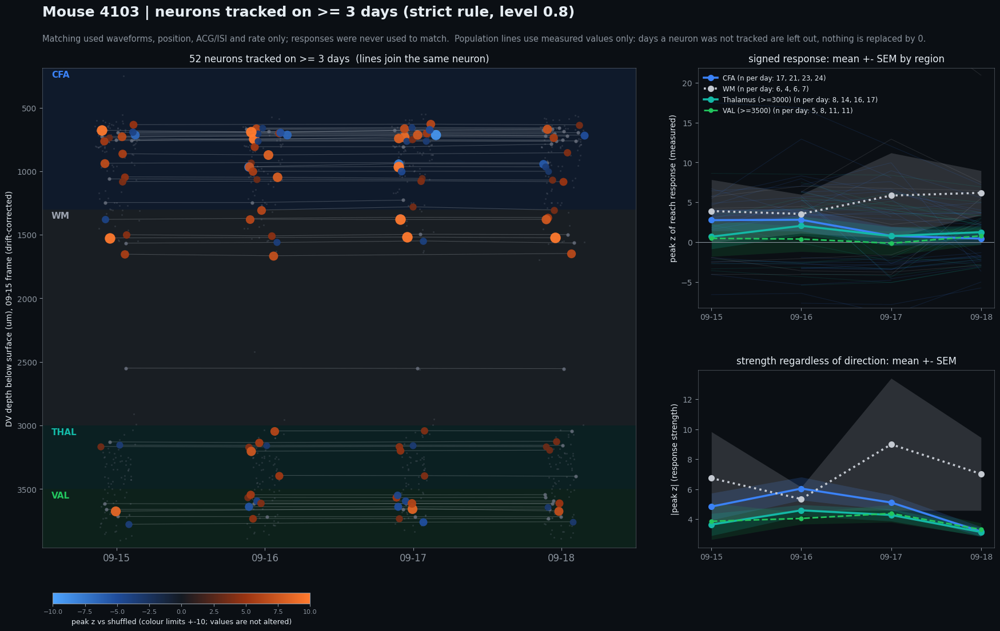

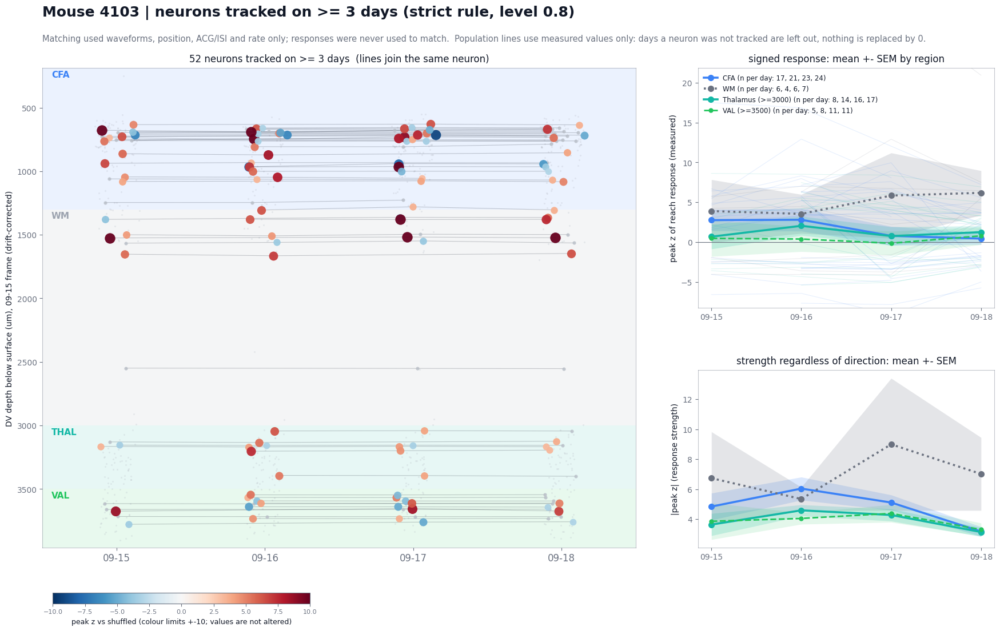

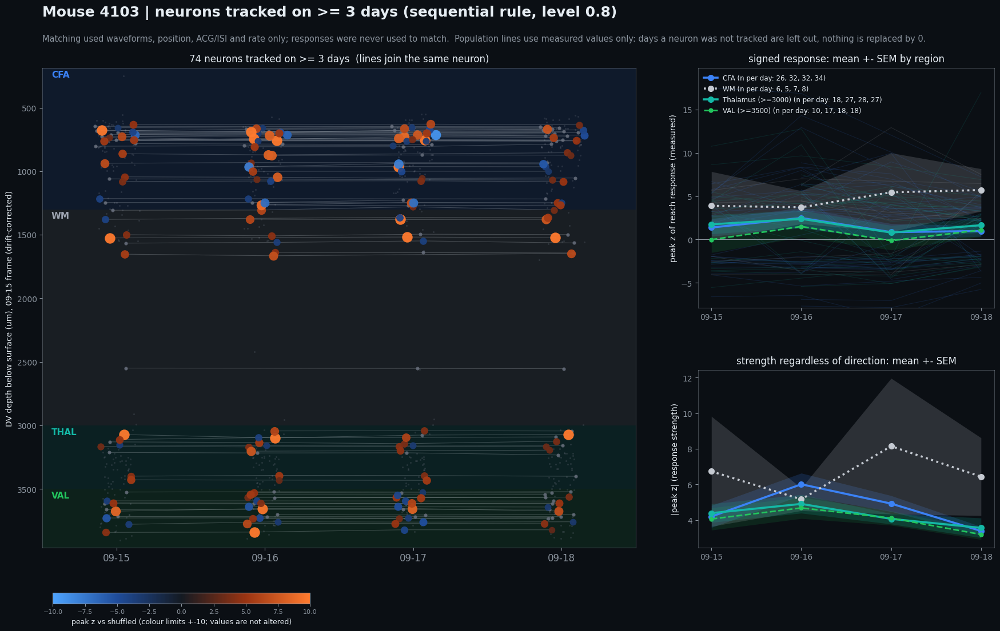

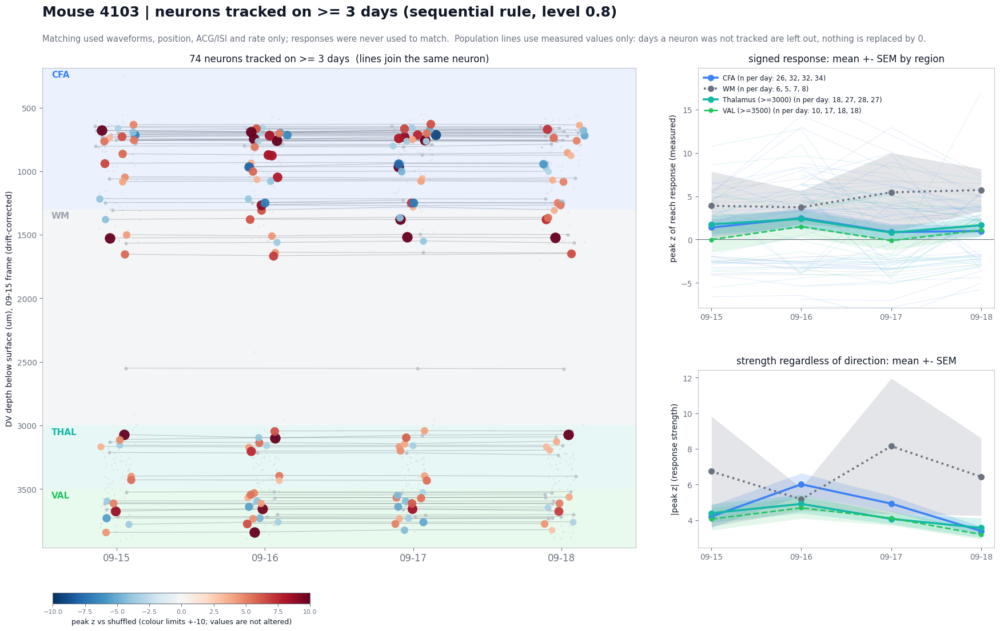

In [13]:
# --- DOWNSTREAM: reach responses of the tracked neurons (never used for matching) ---
from fmpipe import plot_tracked_probe
for rule, tabs in (("strict", out["chains"]), ("sequential", seq_tabs)):
    for L in (0.8,):
        for theme in ("dark", "light"):
            f = plot_tracked_probe(DAYS, profiles, results, days, tabs[L], theme=theme, min_days=3,
                                   title=f"Mouse 4103 | neurons tracked on >= 3 days ({rule} rule, level {L})",
                                   save_path=OUT_DIR + rf"\\tracked_probe_{rule}_p{L:.2f}_{theme}.png")
            if theme == "dark":
                plt.figure(f.number); plt.show()